# Lab01: EDA, preprocessing và feature engineering
Notebook chuẩn bị dữ liệu; đã có output chuẩn bị dữ liệu thực tế; chưa huấn luyện model tại notebook này. Chạy từng cell theo thứ tự. Mọi output tính toán được lưu trong run riêng. Không tạo PDF.

## Bảng Lộ Trình Triển Khai Thực Tế (Pipeline Execution Roadmap)

| Bước | Giai đoạn (Phase) | Nội dung chi tiết (Core Description) | Module triển khai | Sản phẩm đầu ra (Output / Artifact) |
| :---: | :--- | :--- | :--- | :--- |
| **1** | **Setup & Import** | Nhận diện source/output local hoặc Kaggle, cấu hình seed và môi trường. | `src.utils.helpers`<br>`src.utils.runs` | `config.json`<br>`environment_snapshot.json`<br>`console.log` |
| **2** | **Core EDA** | Khảo sát cấu trúc, nhãn, integrity, ảnh trùng, cường độ và hình dáng qua pipeline EDA hiện có. | `src.datasets.eda`<br>`src.utils.plots` | `eda/tables/*.csv`<br>`eda/figures/*.png` |
| **3** | **Split & Preprocessing** | Chia stratified 54.000 train / 6.000 validation; rescale /255; tính mean/std chỉ từ train. | `src.datasets.eda`<br>`src.datasets.base` | `eda/split_indices.npz`<br>`eda/split_metadata.json`<br>`eda/preprocessing_config.json` |
| **4** | **Feature Engineering** | Trích xuất 10 feature trên ảnh [0,1], trước standardization pixel; scaler chỉ fit train. | `src.datasets.features`<br>`src.datasets.preparation` | `train_features.csv`<br>`val_features.csv`<br>`test_features.csv`<br>`feature_scaler.json` |
| **5** | **Feature Visualization** | Minh họa bounding box/trọng tâm, phân bố feature theo lớp và tương quan trên train. | `src.datasets.preparation` | `feature_geometry.png`<br>`feature_distributions.png`<br>`feature_correlations.png`<br>`feature_correlations.csv` |
| **6** | **Data Handoff** | Chuẩn bị pixel 784 chiều và 10 feature chuẩn hóa, nhãn và original indices cho từng split. | `src.datasets.preparation` | `prepared.npz` |
| **7** | **Review & Tracking** | Đọc lại output đã lưu; ghi trạng thái và checksum, giữ log kể cả run thất bại. | `src.utils.runs`<br>`notebook 01` | `status.json`<br>`manifest.json`<br>`output notebook` |

**Quy ước đường dẫn:** output trong bảng nằm tương đối dưới `outputs/runs/<run_id>/` của giai đoạn tương ứng. Mỗi lần chạy tạo thư mục riêng; không dùng đường dẫn output cố định của notebook lịch sử. Roadmap mô tả luồng triển khai, không phải tuyên bố mọi run đều đã hoàn thành.


In [1]:
from pathlib import Path
import sys
candidates = [Path.cwd(), *Path.cwd().parents]
LAB = next((p for p in candidates if (p / 'src/models/mlp.py').is_file()), None)
if LAB is None:
    LAB = next((p / 'labs/lab01' for p in candidates if (p / 'labs/lab01/src/models/mlp.py').is_file()), None)
if LAB is None:
    raise RuntimeError('Set working directory to the repository or lab01 folder; on Kaggle mount/copy the lab source first.')
sys.path.insert(0, str(LAB))
from src.utils.helpers import OUTPUTS_DIR
from IPython.display import display, Image


## 1. Hợp đồng dữ liệu
Ảnh 28×28, 10 lớp. EDA dùng pipeline 9 bước hiện có. Split stratified được lưu. Rescaling chia 255; standardization dùng thống kê train. Feature đo từ ảnh [0,1], trước standardization.

## 2. Trích xuất và bàn giao
10 feature: mean, std, foreground ratio (>0.1), bbox width/height chia 28, aspect ratio, centroid cường độ x/y chia 27, symmetry = 1 - mean absolute mirror difference, edge density = tỷ lệ chênh lệch pixel lân cận >0.1. Ảnh rỗng có bbox/centroid bằng 0, symmetry bằng 1. Scaler fit train; validation/test chỉ transform. Không augmentation ở comparison này.

Run: C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T124545Z_preparation_9cf4ba1f
--- 1. TỔNG QUAN CẤU TRÚC DỮ LIỆU THÔ (STEP 1) ---
Tập dữ liệu  Số lượng ảnh Kích thước (HxW)  Kênh màu Kiểu dữ liệu (dtype) Dải điểm ảnh Dải nhãn (Labels)  Số lớp  Dung lượng RAM (MB)
      train         60000            28x28         1                uint8     [0, 255]            [0, 9]      10                44.86
       test         10000            28x28         1                uint8     [0, 255]            [0, 9]      10                 7.48

--- 2. KIỂM TRA TÍNH TOÀN VẸN & CHỐNG RÒ RỈ (STEP 2) ---
            Hạng mục kiểm tra Kết quả mong đợi                       Thực tế Trạng thái
   Giá trị thiếu (NaN / Null)         Không có                      Không có     PASSED
Dải giá trị điểm ảnh [0, 255]   [0, 255] uint8 Train [0, 255], Test [0, 255]     PASSED
    Dải nhãn phân loại [0, 9]    10 lớp [0, 9]     Train [0, 9], Test [0, 9]     PASSED
   Trùng lặp nội bộ tập Train      0 

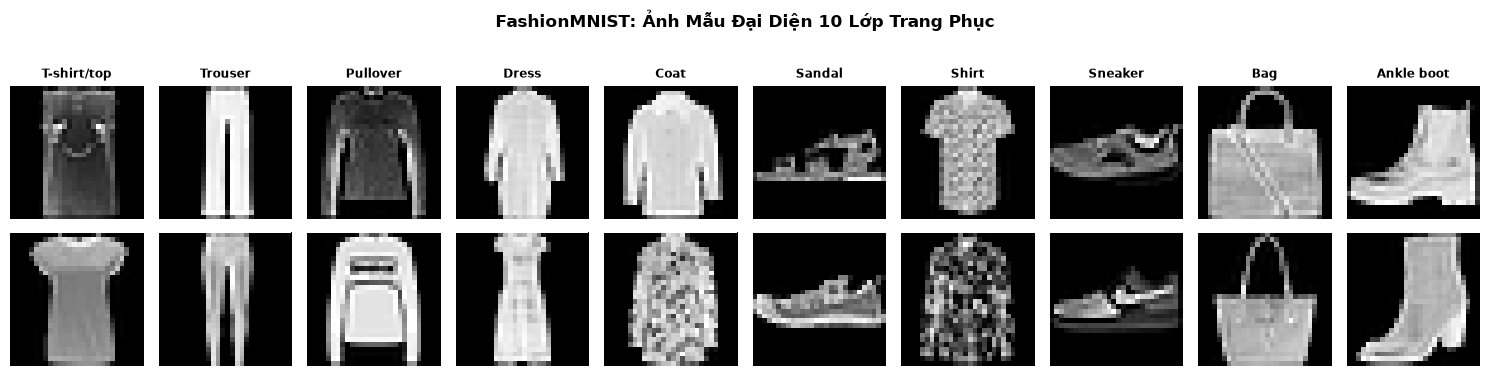

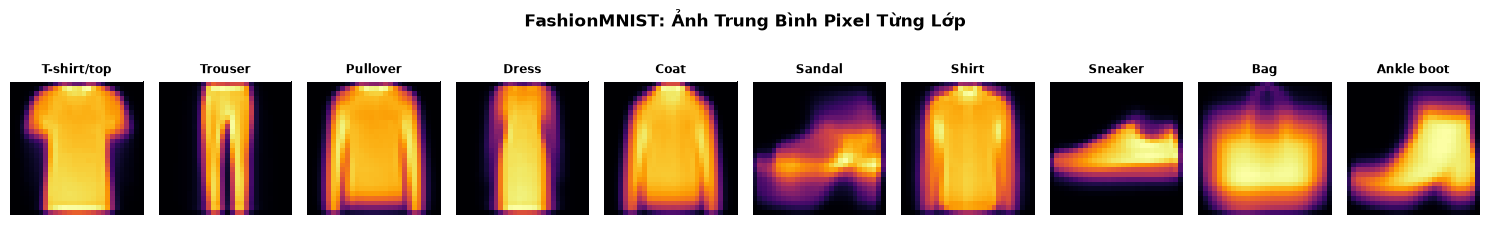

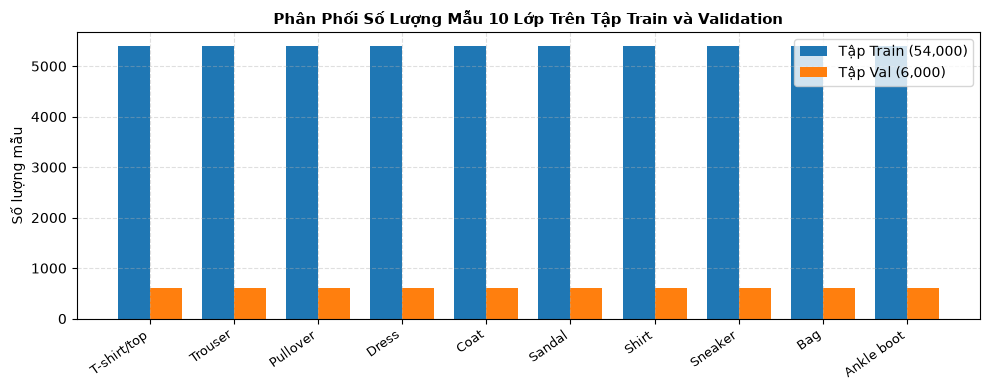

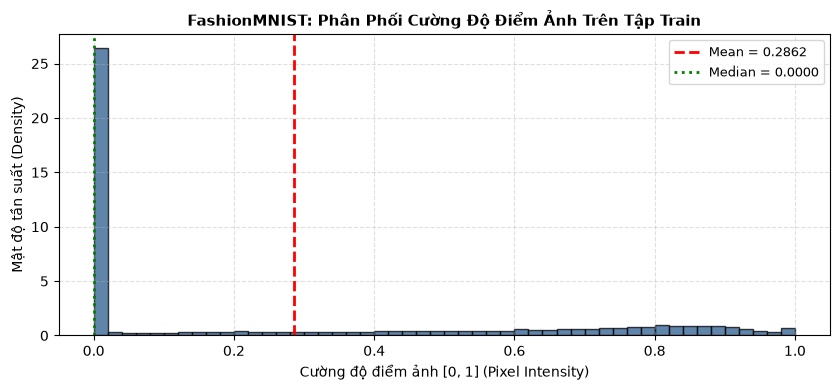

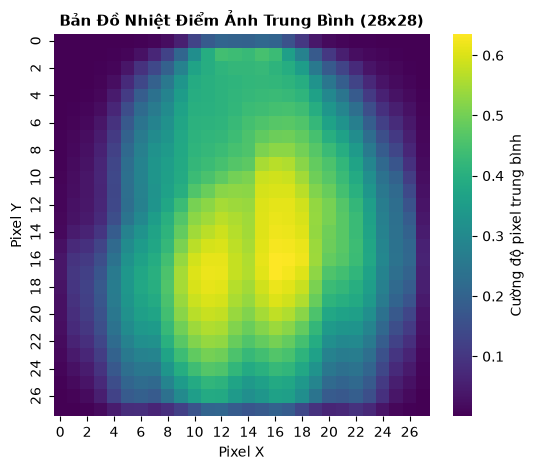

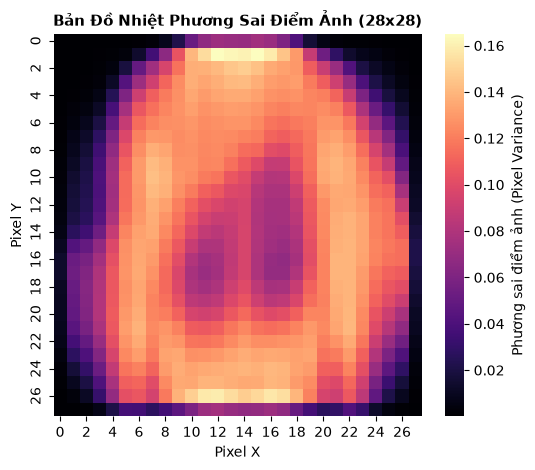

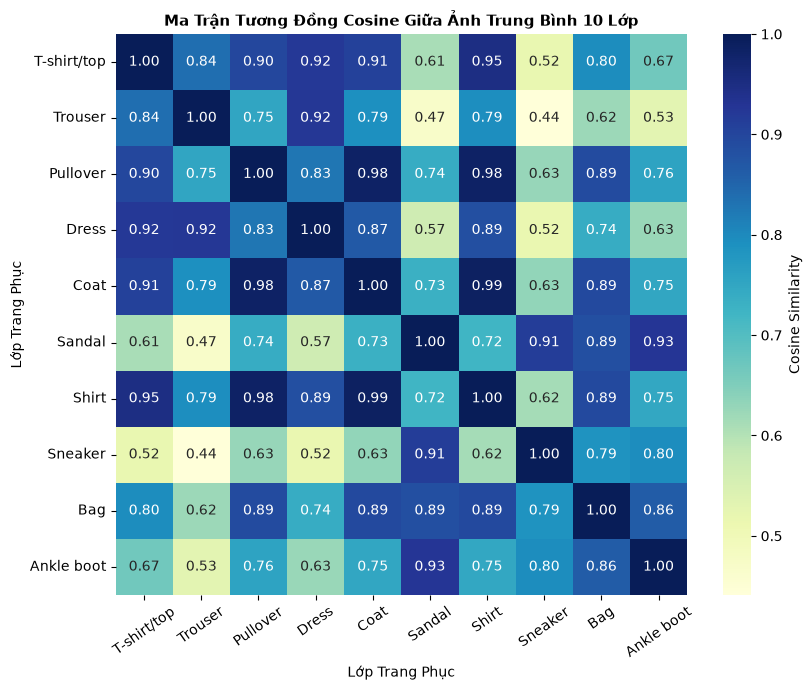

In [2]:
from src.datasets.preparation import prepare_data
PREPARATION_RUN = prepare_data(seed=42)


## 3. Đọc output đã lưu
Bảng đầy đủ nằm trong artifact; cell hiển thị bản đọc lại, không sinh kết quả độc lập chưa lưu.

class_distribution.csv


,split,label,class_name,count,percent,split_total
0,train,0,T-shirt/top,5400,10.0,54000
1,train,1,Trouser,5400,10.0,54000
2,train,2,Pullover,5400,10.0,54000
3,train,3,Dress,5400,10.0,54000
4,train,4,Coat,5400,10.0,54000


class_similarity_matrix.csv


,Unnamed: 0,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
0,T-shirt/top,1.000000,0.837096,0.899379,0.923231,0.906569,0.609367,0.949727,0.518767,0.795559,0.668001
1,Trouser,0.837096,1.000000,0.752760,0.924922,0.792135,0.470852,0.794210,0.441012,0.623250,0.529858
2,Pullover,0.899379,0.752760,1.000000,0.826782,0.984075,0.738854,0.982976,0.627331,0.892757,0.755979
3,Dress,0.923231,0.924922,0.826782,1.000000,0.867507,0.567046,0.885337,0.517153,0.739770,0.625775
4,Coat,0.906569,0.792135,0.984075,0.867507,1.000000,0.732131,0.987286,0.632184,0.893556,0.749478


handcrafted_features.csv


...

spatial_features.csv


,source_dataset,original_index,split,label,class_name,foreground_threshold,foreground_ratio,bbox_height,bbox_width,bbox_aspect_ratio,bbox_area_ratio,empty_foreground
0,original_train,36094,train,8,Bag,0.1,0.628827,28,24,0.857143,0.857143,False
1,original_train,15200,train,9,Ankle boot,0.1,0.465561,22,28,1.272727,0.785714,False
2,original_train,41009,train,8,Bag,0.1,0.429847,28,22,0.785714,0.785714,False
3,original_train,52507,train,0,T-shirt/top,0.1,0.529337,28,17,0.607143,0.607143,False
4,original_train,7279,train,1,Trouser,0.1,0.340561,28,11,0.392857,0.392857,False


structural_overview.csv


,Tập dữ liệu,Số lượng ảnh,Kích thước (HxW),Kênh màu,Kiểu dữ liệu (dtype),Dải điểm ảnh,Dải nhãn (Labels),Số lớp,Dung lượng RAM (MB)
0,train,60000,28x28,1,uint8,"[0, 255]","[0, 9]",10,44.86
1,test,10000,28x28,1,uint8,"[0, 255]","[0, 9]",10,7.48


eda\figures\class_distribution.png


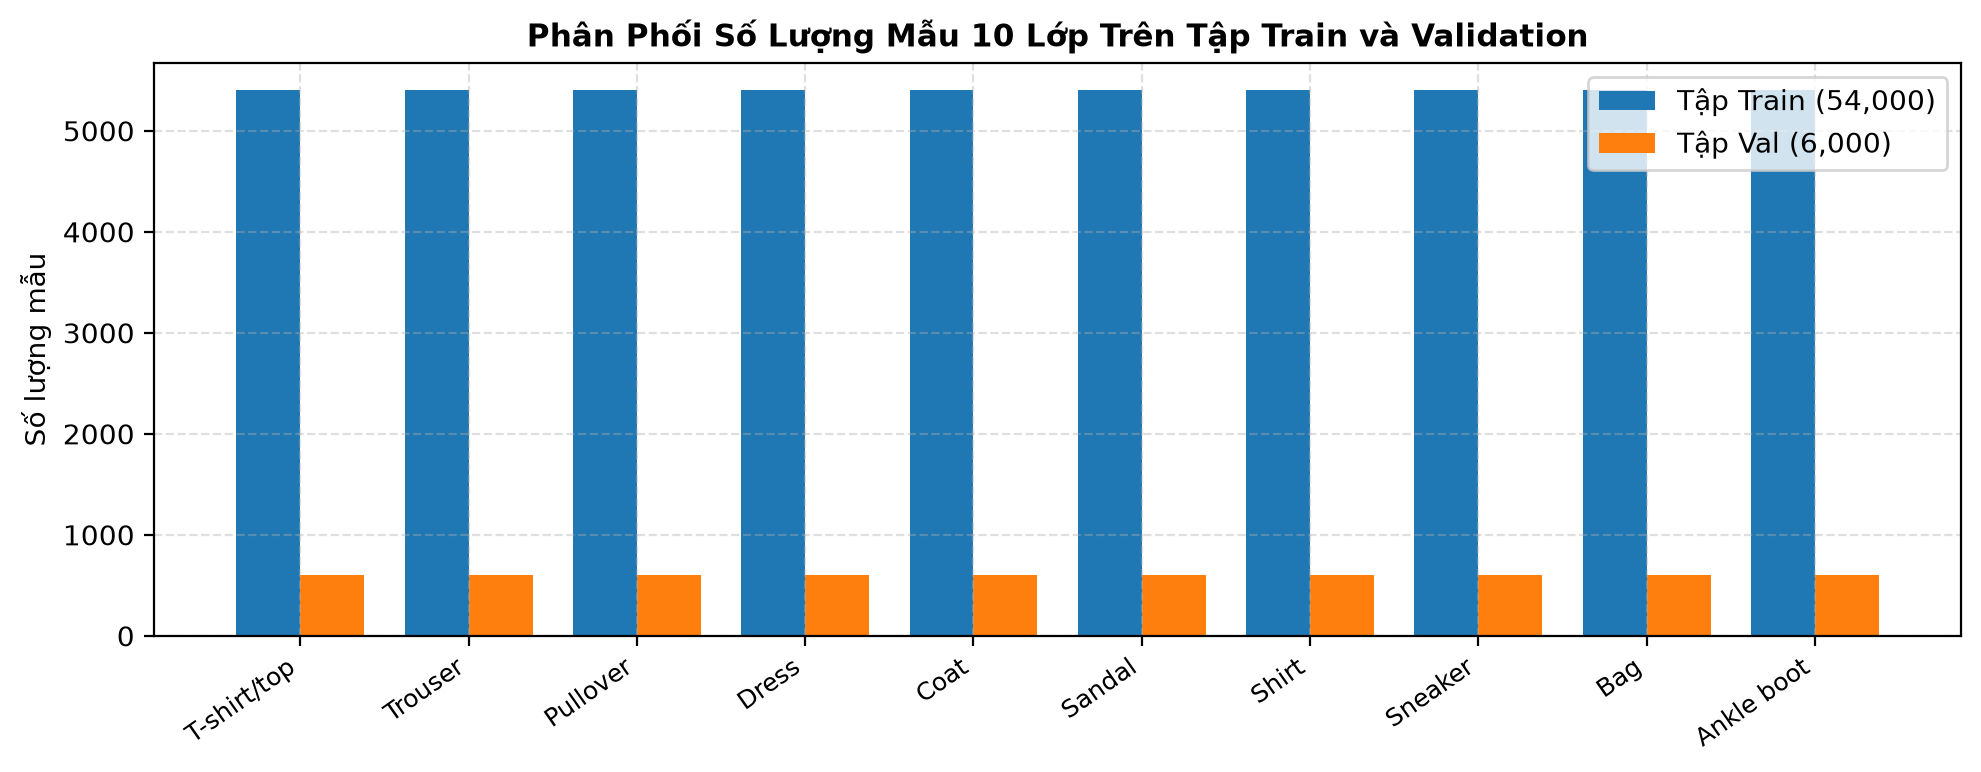

eda\figures\class_mean_images.png


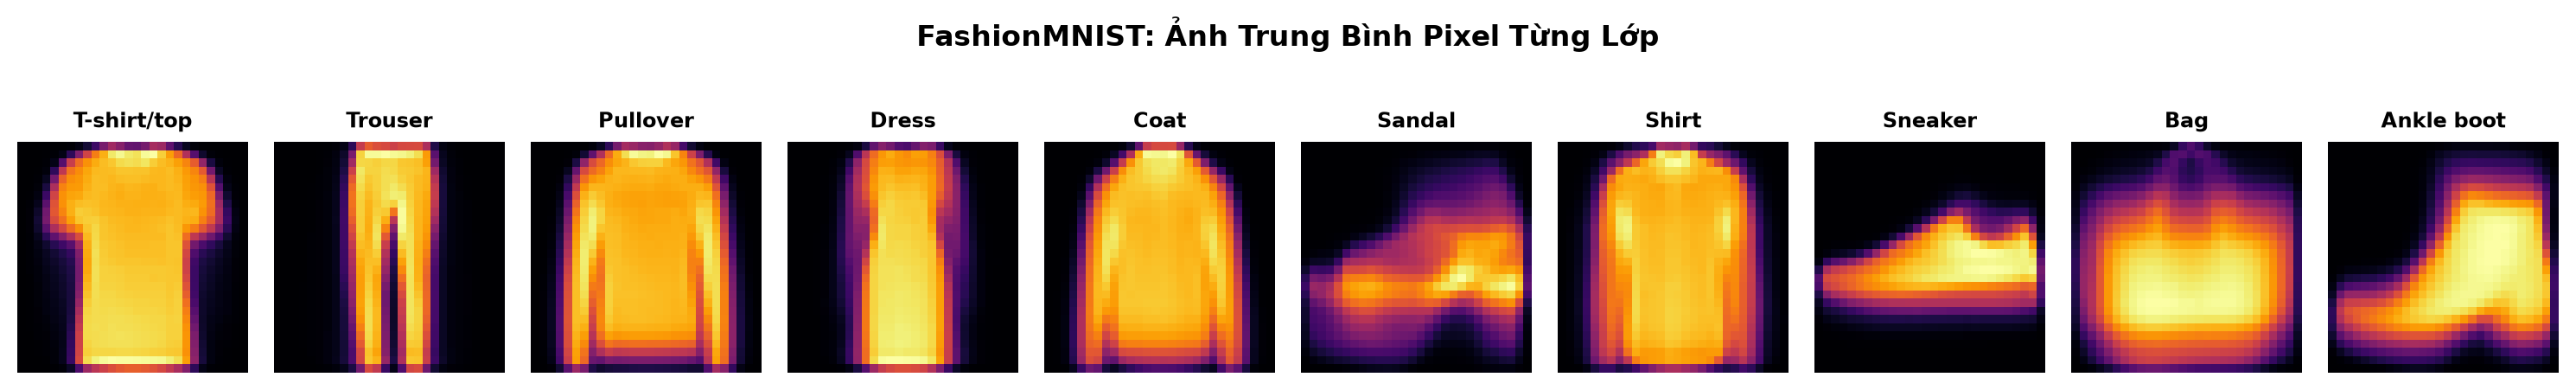

eda\figures\class_similarity_heatmap.png


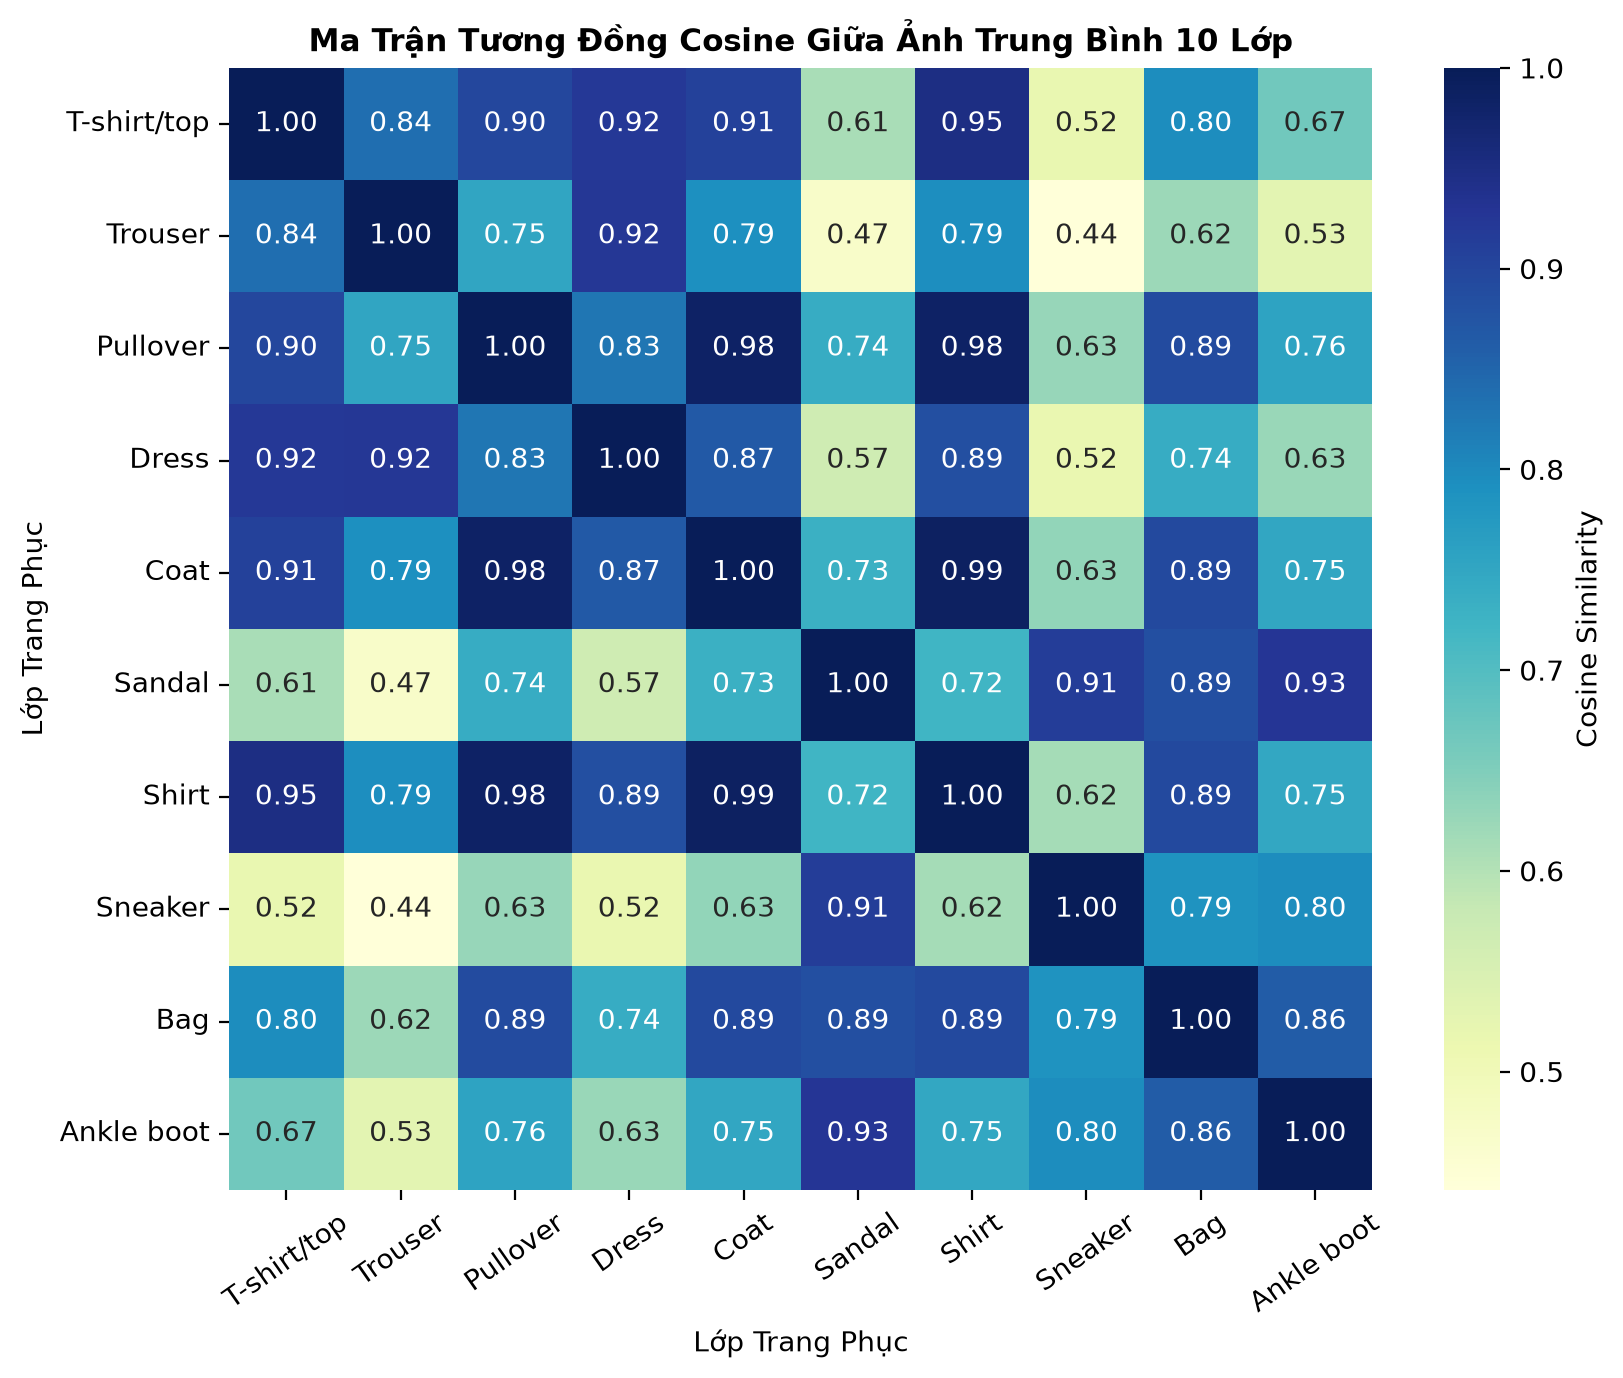

eda\figures\mean_pixel_heatmap.png


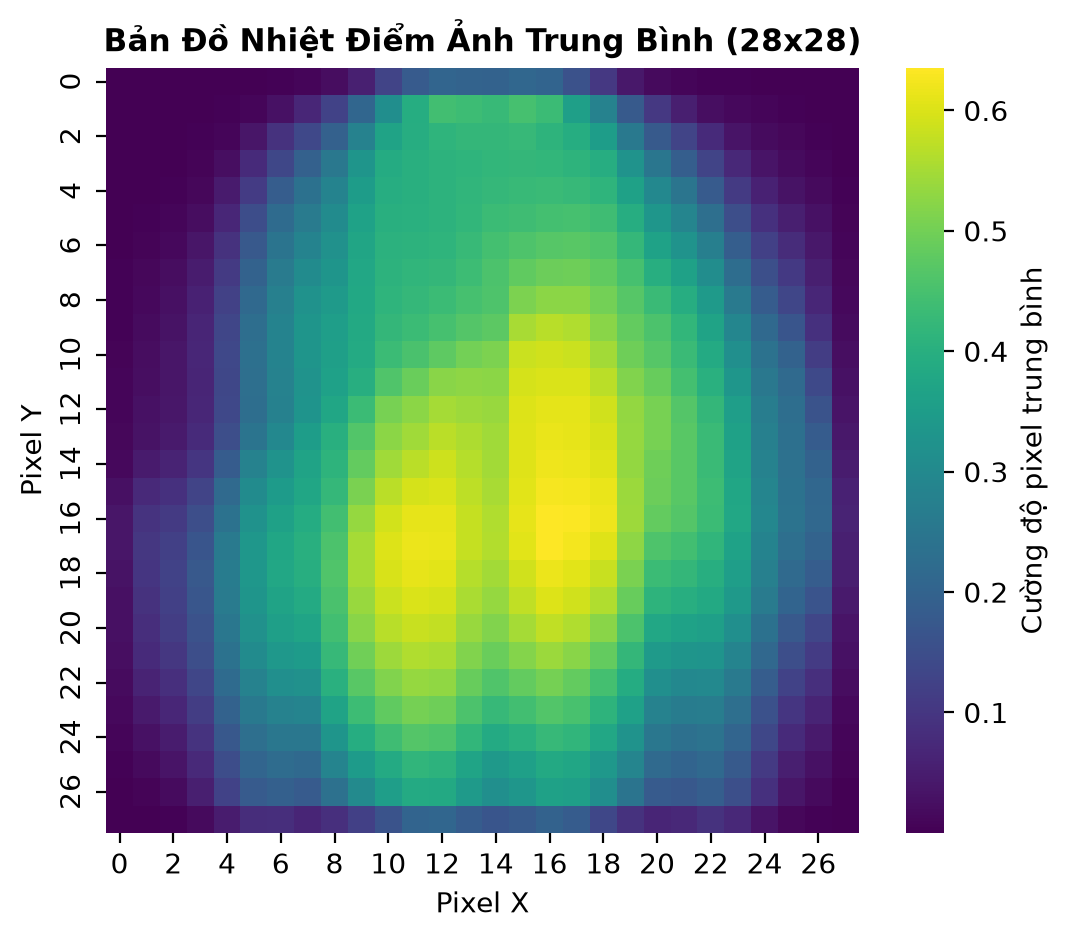

eda\figures\pixel_histogram.png


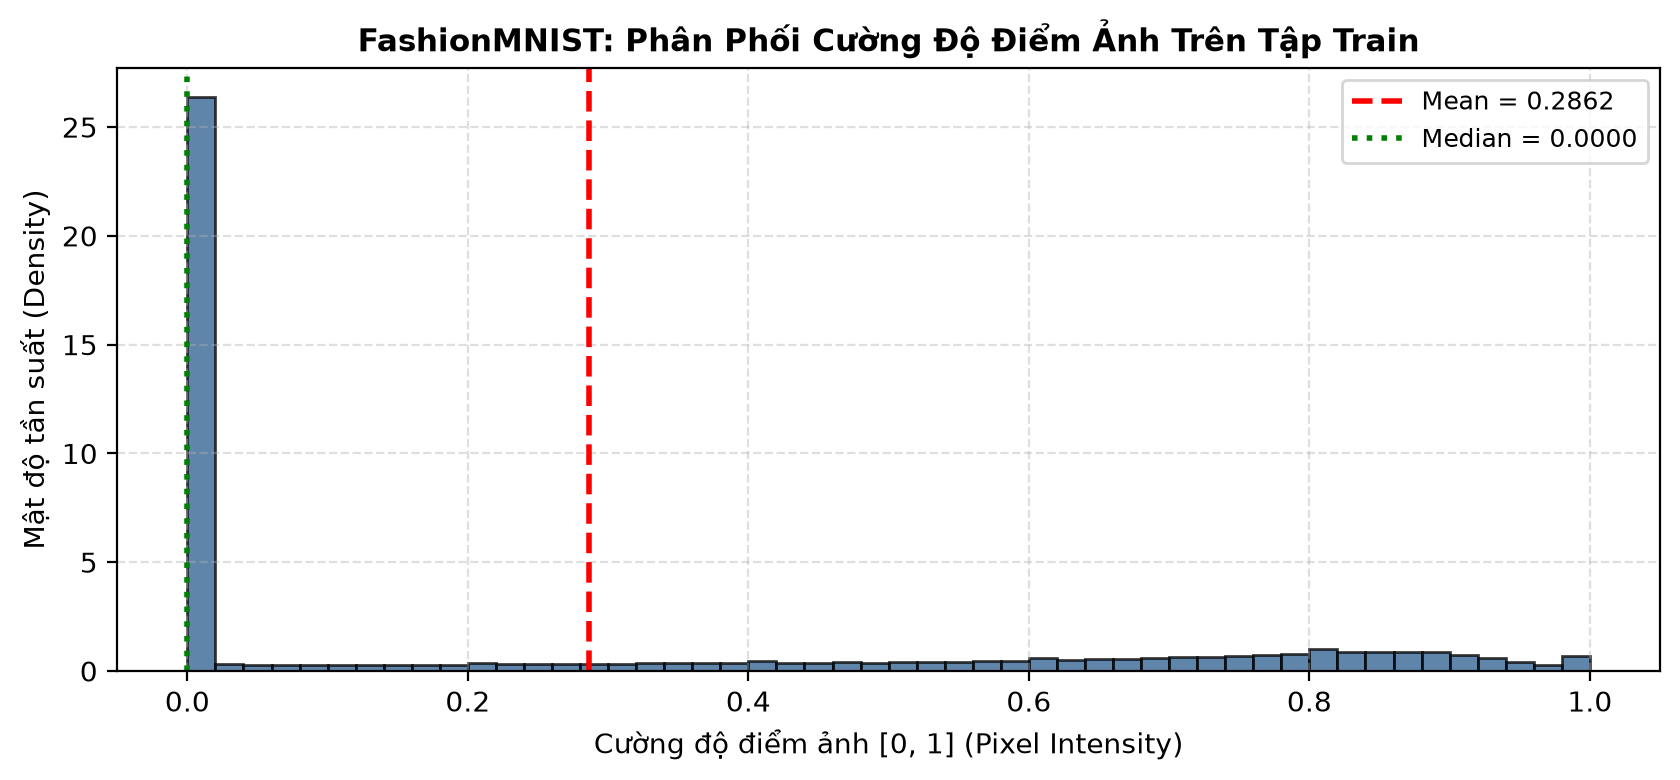

eda\figures\pixel_variance_heatmap.png


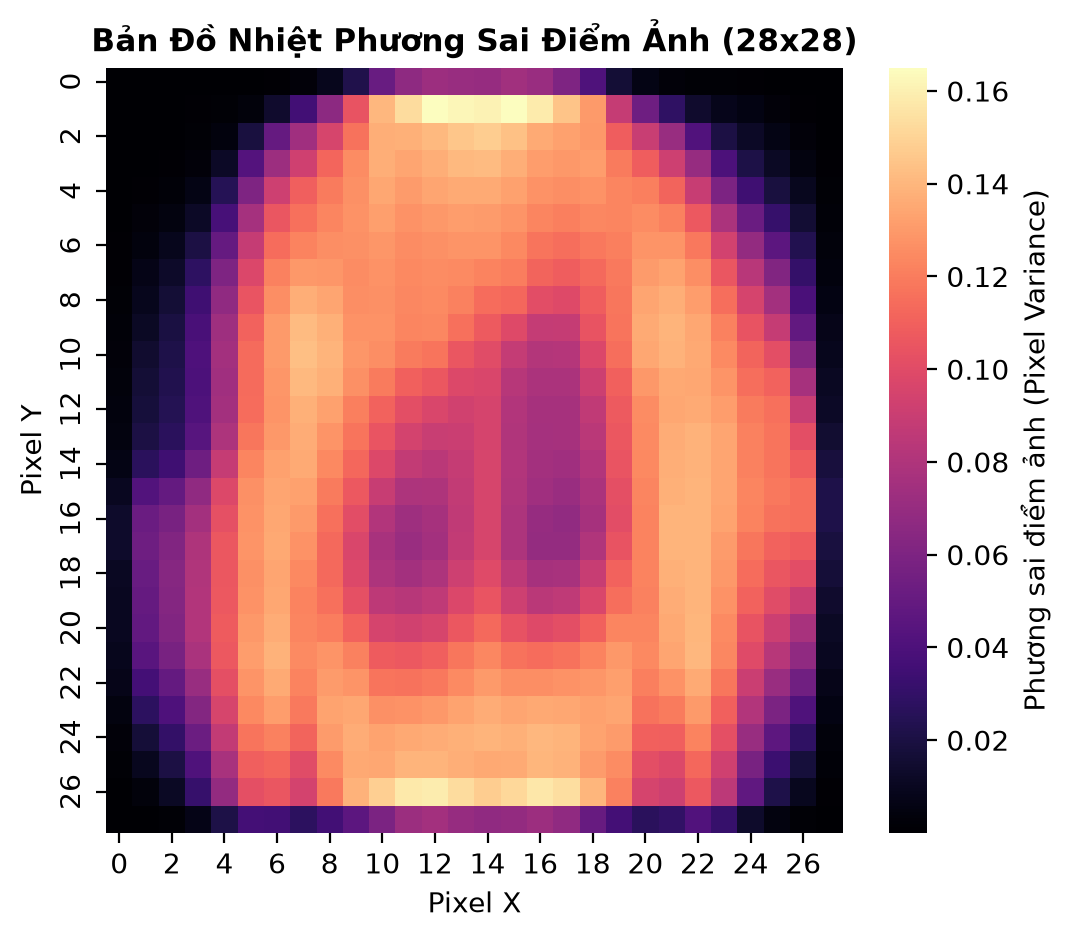

eda\figures\sample_images.png


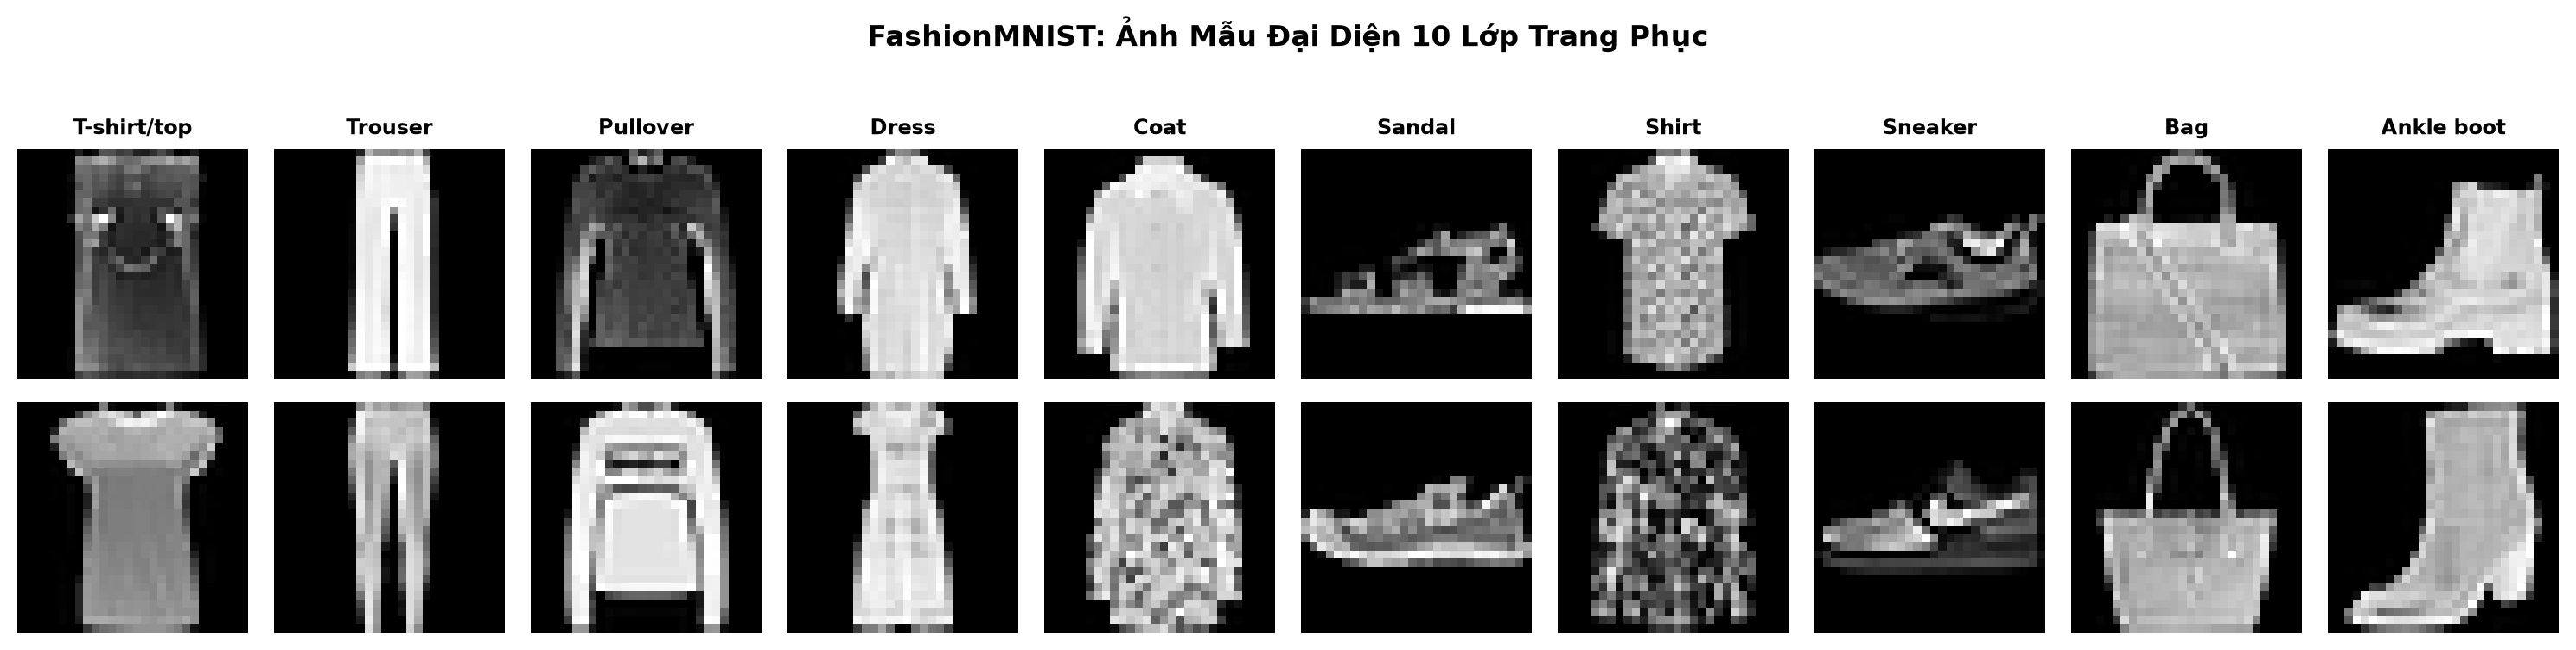

feature_correlations.png


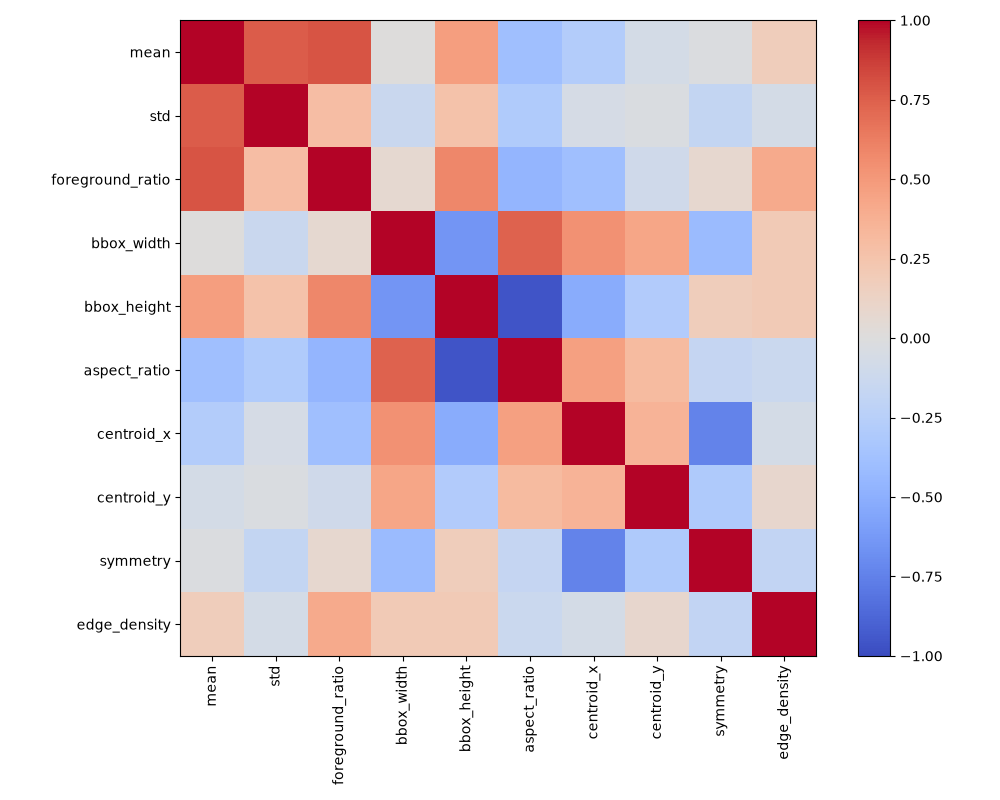

feature_distributions.png


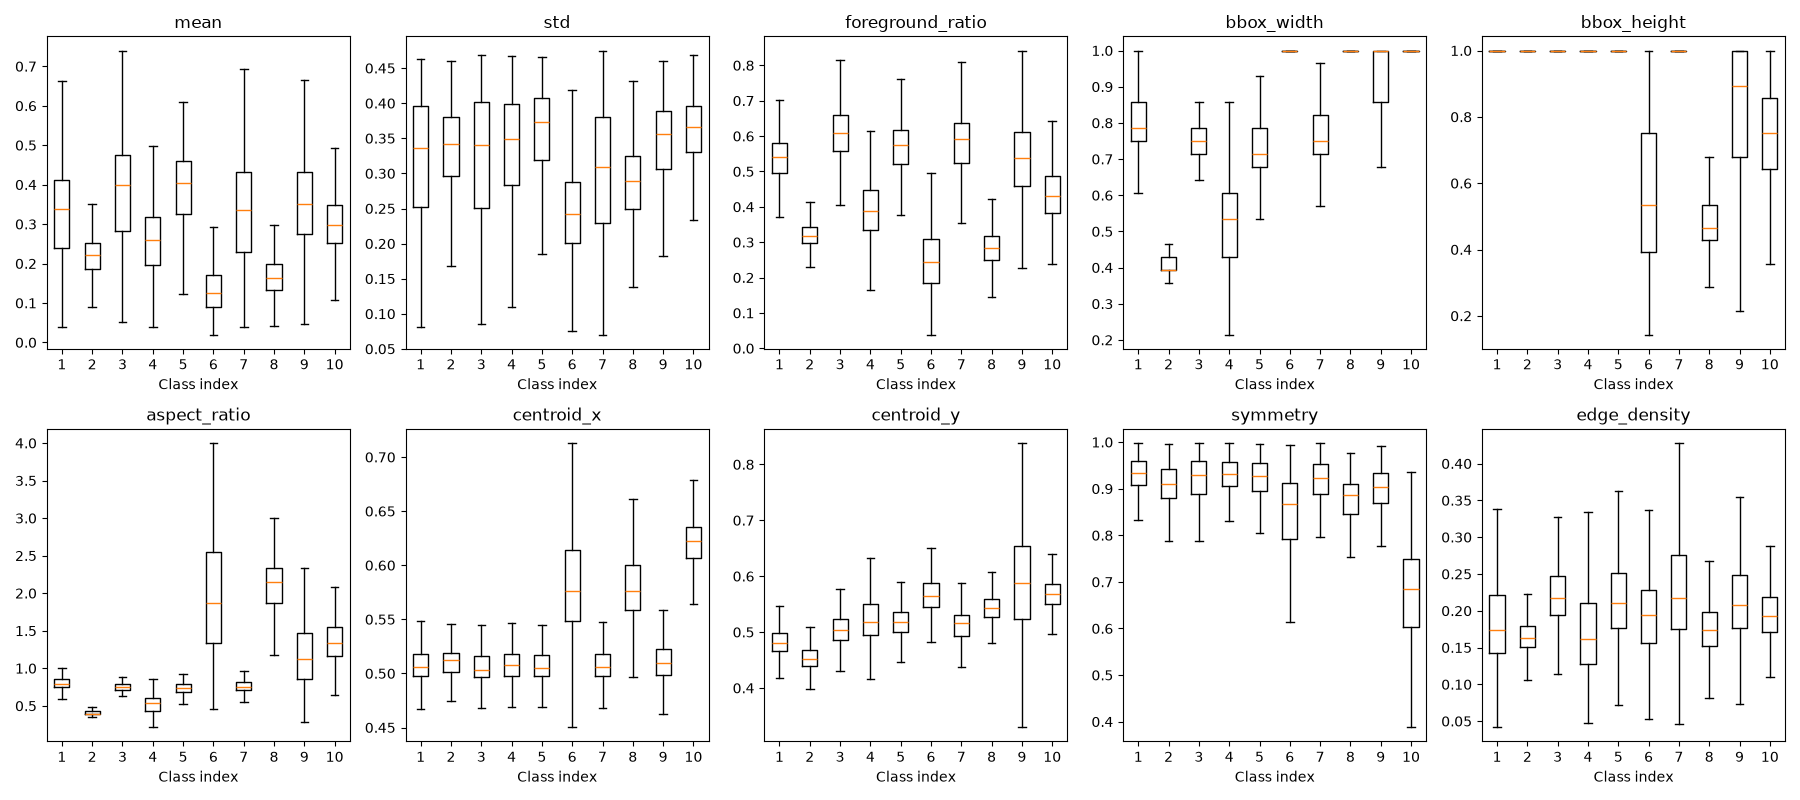

feature_geometry.png


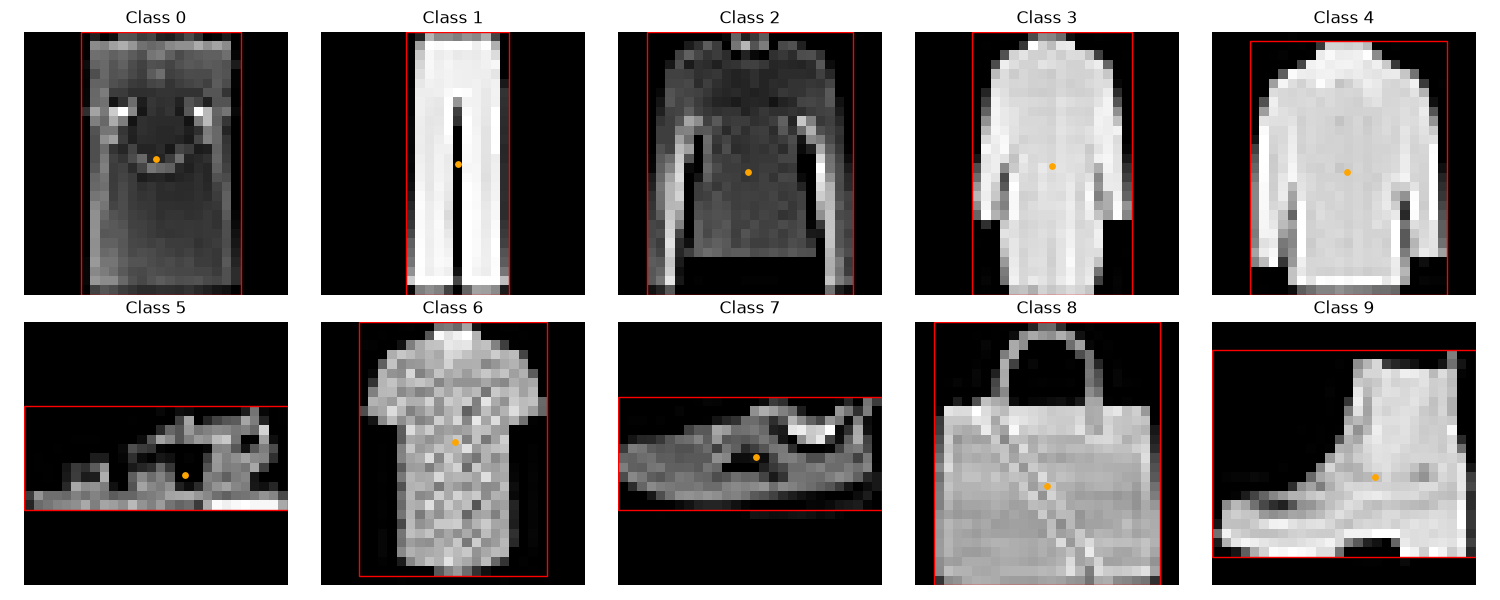

In [3]:
import pandas as pd
for p in sorted((PREPARATION_RUN / 'eda/tables').glob('*.csv')):
    print(p.name)
    display(pd.read_csv(p).head())
for p in sorted(PREPARATION_RUN.rglob('*.png')):
    print(p.relative_to(PREPARATION_RUN))
    display(Image(filename=str(p)))

## 4. Bàn giao sang modeling
Copy đường dẫn prepared.npz vào notebook 02. Giữ nguyên thư mục run chứa split, config và scaler; không chỉ di chuyển riêng file NPZ.

In [4]:
print(PREPARATION_RUN / 'prepared.npz')

C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\runs\20261022T124545Z_preparation_9cf4ba1f\prepared.npz
